In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project folder
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Load the cleaned movie dataset
CSV_FILE = PROJECT_ROOT / "data" / "processed" / "tmdb_movies_clean.csv"
df = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nFirst five movies:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (18, 22)

First five movies:


,id,title,tagline,release_date,genres,belongs_to_collection,original_language,budget_musd,revenue_musd,production_companies,...,vote_average,popularity,runtime,overview,spoken_languages,poster_path,cast,cast_size,director,crew_size
0,299534,Avengers: Endgame,Avenge the fallen.,2019-04-24,Adventure|Science Fiction|Action,The Avengers Collection,en,356.0,2927.449455,Marvel Studios,...,8.200,85.6868,181.0,After the devastating events of Avengers: Infi...,English|日本語,/bR8ISy1O9XQxqiy0fQFw2BX72RQ.jpg,Robert Downey Jr.|Chris Evans|Mark Ruffalo|Chr...,103,Anthony Russo|Joe Russo,613
1,19995,Avatar,Enter the world of Pandora.,2009-12-16,Science Fiction|Action|Adventure,Avatar Collection,en,237.0,2923.706026,Dune Entertainment|Lightstorm Entertainment|20...,...,7.611,54.7684,162.0,"In the 22nd century, a paraplegic Marine is di...",English|Español,/gKY6q7SjCkAU6FqvqWybDYgUKIF.jpg,Sam Worthington|Zoe Saldaña|Sigourney Weaver|S...,68,James Cameron,999
2,140607,Star Wars: The Force Awakens,Every generation has a story.,2015-12-15,Adventure|Action|Science Fiction,Star Wars Collection,en,245.0,2068.223624,Lucasfilm Ltd.|Bad Robot,...,7.200,33.9297,136.0,Thirty years after defeating the Galactic Empi...,English,/wqnLdwVXoBjKibFRR5U3y0aDUhs.jpg,Daisy Ridley|John Boyega|Oscar Isaac|Adam Driv...,99,J.J. Abrams,270
3,299536,Avengers: Infinity War,An entire universe. Once and for all.,2018-04-25,Adventure|Action|Science Fiction,The Avengers Collection,en,300.0,2052.415039,Marvel Studios,...,8.245,120.2515,149.0,As the Avengers and their allies have continue...,English,/7WsyChQLEftFiDOVTGkv3hFpyyt.jpg,Robert Downey Jr.|Chris Evans|Chris Hemsworth|...,69,Joe Russo|Anthony Russo,738
4,597,Titanic,Nothing on earth could come between them.,1997-12-18,Drama|Romance,NaN,en,200.0,2264.162353,Paramount Pictures|20th Century Fox|Lightstorm...,...,7.901,57.4984,194.0,101-year-old Rose DeWitt Bukater tells the sto...,English|Français|Deutsch|svenska|Italiano|Pусский,/9xjZS2rlVxm8SFx8kPC3aIGCOYQ.jpg,Leonardo DiCaprio|Kate Winslet|Billy Zane|Kath...,116,James Cameron,271


Dataset loaded successfully!
Dataset shape: (18, 22)

First five movies:

In [2]:
# Display dataset information
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values per column:")
display(
    df.isnull()
    .sum()
    .sort_values(ascending=False)
    .to_frame(name="Missing Values")
)

# Check duplicate records
print("\nDuplicate movie IDs:", df["id"].duplicated().sum())

# Display summary statistics
print("\nSummary statistics:")
display(df.describe().round(2))

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     18 non-null     int64  
 1   title                  18 non-null     str    
 2   tagline                18 non-null     str    
 3   release_date           18 non-null     str    
 4   genres                 18 non-null     str    
 5   belongs_to_collection  16 non-null     str    
 6   original_language      18 non-null     str    
 7   budget_musd            18 non-null     float64
 8   revenue_musd           18 non-null     float64
 9   production_companies   18 non-null     str    
 10  production_countries   18 non-null     str    
 11  vote_count             18 non-null     int64  
 12  vote_average           18 non-null     float64
 13  popularity             18 non-null     float64
 14  runtime                18 non-null     float64
 15

,Missing Values
belongs_to_collection,2
id,0
title,0
tagline,0
release_date,0
genres,0
original_language,0
budget_musd,0
revenue_musd,0
production_companies,0



Duplicate movie IDs: 0

Summary statistics:


,id,budget_musd,revenue_musd,vote_count,vote_average,popularity,runtime,cast_size,crew_size
count,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00,18.00
mean,192258.44,213.78,1699.04,21716.94,7.39,50.04,138.00,79.94,390.67
std,132476.95,61.96,537.61,8733.41,0.53,23.81,23.85,30.99,260.02
min,597.00,125.00,1243.23,10515.00,6.52,29.66,102.00,20.00,43.00
25%,102257.00,162.50,1336.18,14566.50,7.12,34.47,125.25,61.00,212.00
50%,175033.50,200.00,1484.54,21513.50,7.26,39.40,135.50,72.00,279.50
75%,299535.50,243.00,1957.20,27220.75,7.83,56.82,147.50,106.00,606.25
max,420818.00,356.00,2927.45,40038.00,8.24,120.25,194.00,139.00,999.00


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is used to understand the main characteristics of the movie dataset. This section examines release dates, financial performance, audience ratings, popularity, and genres to identify useful patterns.

In [3]:
# Convert release_date to a proper date format
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

# Extract release year for analysis
df["release_year"] = df["release_date"].dt.year

print("Number of movies:", len(df))
print("Earliest release date:", df["release_date"].min().date())
print("Latest release date:", df["release_date"].max().date())

print("\nNumerical summary:")
display(
    df[
        [
            "budget_musd",
            "revenue_musd",
            "vote_average",
            "vote_count",
            "popularity",
            "runtime",
        ]
    ].describe().round(2)
)

print("\nMovies released per year:")
display(df["release_year"].value_counts().sort_index().to_frame("Movie Count"))

Number of movies: 18
Earliest release date: 1997-12-18
Latest release date: 2019-11-20

Numerical summary:


,budget_musd,revenue_musd,vote_average,vote_count,popularity,runtime
count,18.00,18.00,18.00,18.00,18.00,18.00
mean,213.78,1699.04,7.39,21716.94,50.04,138.00
std,61.96,537.61,0.53,8733.41,23.81,23.85
min,125.00,1243.23,6.52,10515.00,29.66,102.00
25%,162.50,1336.18,7.12,14566.50,34.47,125.25
50%,200.00,1484.54,7.26,21513.50,39.40,135.50
75%,243.00,1957.20,7.83,27220.75,56.82,147.50
max,356.00,2927.45,8.24,40038.00,120.25,194.00



Movies released per year:


,Movie Count
release_year,
1997,1
2009,1
2011,1
2012,1
2013,1
2015,4
2017,2
2018,4
2019,3


### 2.1 Movie Budget vs. Revenue

This scatter plot compares each movie's production budget with its box-office revenue. Each point represents one movie. The chart helps us examine whether movies with higher production budgets tend to generate higher revenue.

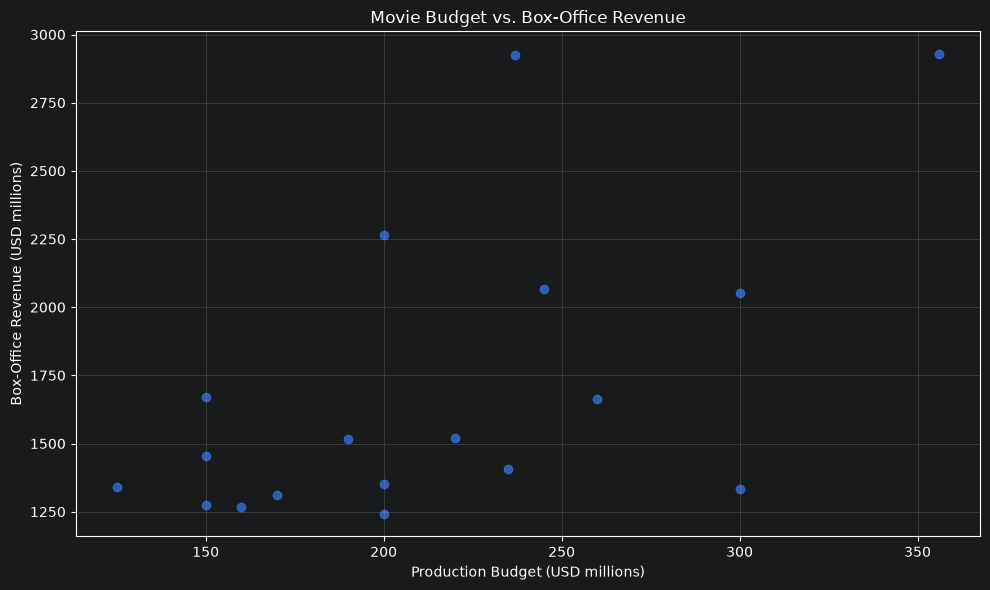

In [4]:
# Select movies with valid budget and revenue
plot_df = df.dropna(subset=["budget_musd", "revenue_musd"])

plt.figure(figsize=(10, 6))

plt.scatter(
    plot_df["budget_musd"],
    plot_df["revenue_musd"],
    alpha=0.8
)

plt.title("Movie Budget vs. Box-Office Revenue")
plt.xlabel("Production Budget (USD millions)")
plt.ylabel("Box-Office Revenue (USD millions)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "budget_vs_revenue.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 2.2 Return on Investment (ROI) by Genre

This analysis calculates the return on investment for each movie and compares ROI across genres. ROI is calculated using production budget and box-office revenue. The results are descriptive and do not include marketing, distribution, taxes, or other costs.

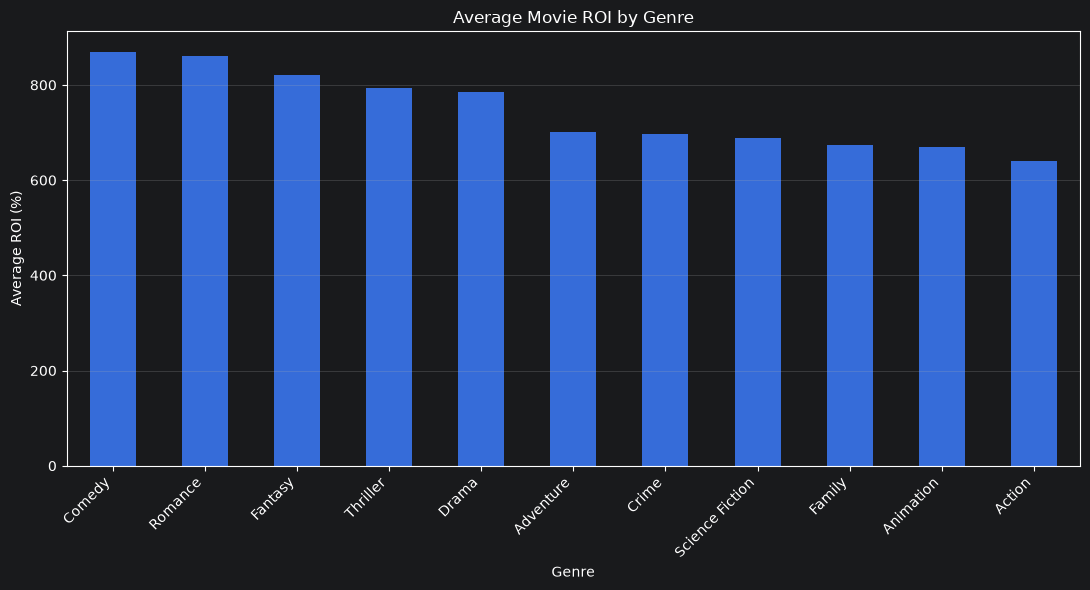

,Average ROI (%)
genre,
Comedy,869.12
Romance,861.70
Fantasy,820.78
Thriller,794.27
Drama,785.66
Adventure,702.02
Crime,697.58
Science Fiction,687.77
Family,674.16


In [9]:
# Calculate ROI for movies with a positive budget
roi_df = df[
    df["budget_musd"].notna()
    & df["revenue_musd"].notna()
    & (df["budget_musd"] > 0)
].copy()

roi_df["roi_percent"] = (
    (roi_df["revenue_musd"] - roi_df["budget_musd"])
    / roi_df["budget_musd"]
) * 100

# Split movies with multiple genres into separate rows
genre_df = roi_df.assign(
    genre=roi_df["genres"].str.split("|")
).explode("genre")

genre_df["genre"] = genre_df["genre"].str.strip()
genre_df = genre_df[genre_df["genre"] != ""]

# Calculate average ROI for each genre
genre_roi = (
    genre_df.groupby("genre")["roi_percent"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(11, 6))
genre_roi.plot(kind="bar")

plt.title("Average Movie ROI by Genre")
plt.xlabel("Genre")
plt.ylabel("Average ROI (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "Average Movie ROI by Genre.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(genre_roi.round(2).to_frame("Average ROI (%)"))

### 2.3 Movie Popularity vs. Audience Rating

This scatter plot examines the relationship between TMDB popularity and average audience ratings. Each point represents a movie. Popularity and audience rating measure different things, so a highly popular movie does not necessarily have the highest rating.

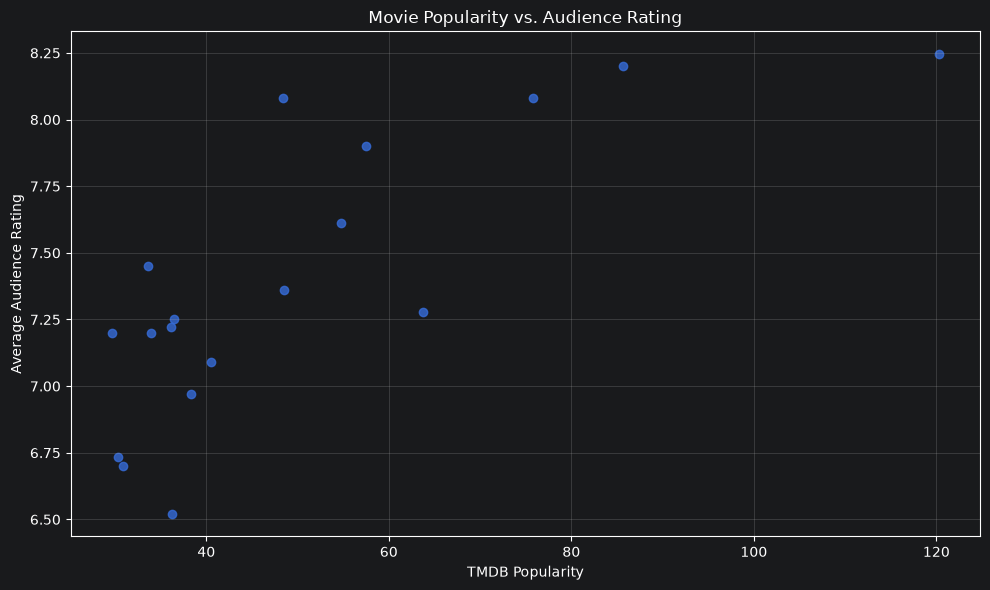

In [6]:
 # Select movies with valid popularity and rating values
popularity_df = df.dropna(
    subset=["popularity", "vote_average"]
)

plt.figure(figsize=(10, 6))

plt.scatter(
    popularity_df["popularity"],
    popularity_df["vote_average"],
    alpha=0.8
)

plt.title("Movie Popularity vs. Audience Rating")
plt.xlabel("TMDB Popularity")
plt.ylabel("Average Audience Rating")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "popularity_vs_rating.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 2.4 Yearly Box-Office Performance

This analysis groups movies by release year and calculates their combined box-office revenue. The bar chart helps compare the total revenue of the sampled movies across different years. Because the dataset contains a selected sample rather than all films released each year, the results do not represent the entire film industry.

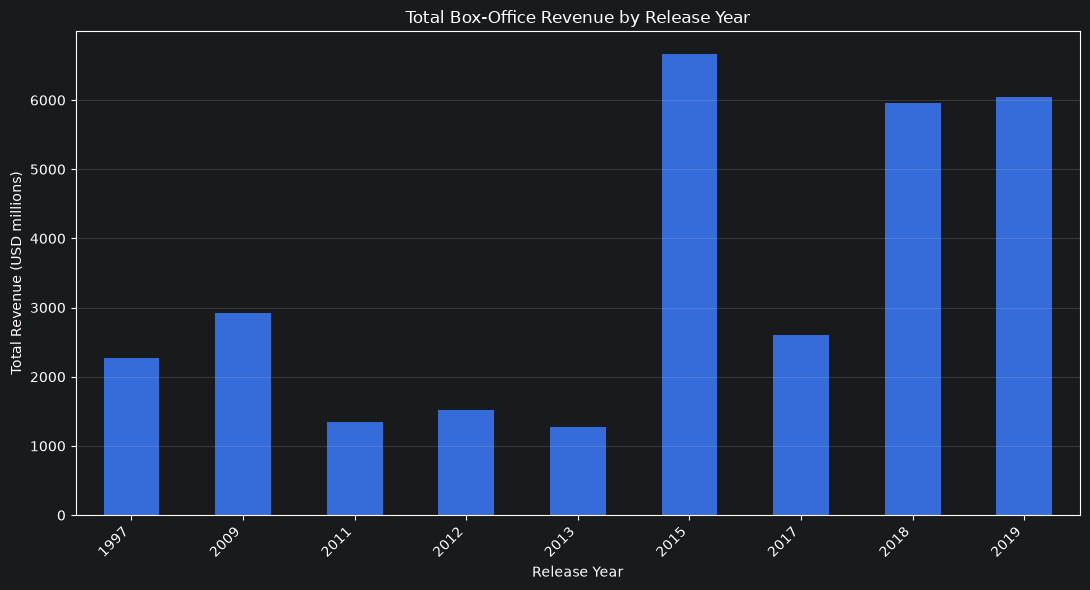

,Total Revenue (USD millions)
release_year,
1997,2264.16
2009,2923.71
2011,1341.51
2012,1518.82
2013,1274.22
2015,6660.56
2017,2600.52
2018,5956.04
2019,6043.15


In [7]:
# Group movies by release year
yearly_revenue = (
    df.dropna(subset=["release_year", "revenue_musd"])
    .groupby("release_year")["revenue_musd"]
    .sum()
    .sort_index()
)

plt.figure(figsize=(11, 6))

yearly_revenue.plot(kind="bar")

plt.title("Total Box-Office Revenue by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Total Revenue (USD millions)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "yearly_box_office.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(
    yearly_revenue.round(2)
    .to_frame("Total Revenue (USD millions)")
)

### 2.5 Franchise vs. Standalone Movie Performance

This analysis compares movies belonging to a TMDB collection with movies that do not belong to a collection. We compare average box-office revenue and average ROI to explore differences in financial performance. The results are descriptive and should be interpreted cautiously because the sample contains far more franchise movies than standalone movies.

,movie_count,average_revenue_musd,average_roi_percent
movie_type,,,
Franchise,16,1690.78,701.74
Standalone,2,1765.14,861.70


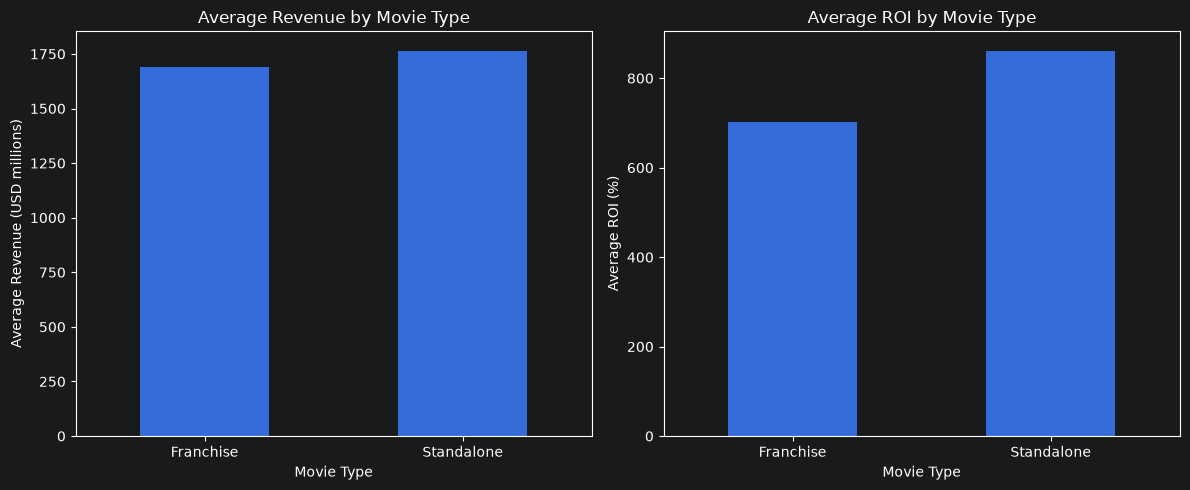

In [8]:
# Classify movies based on whether they belong to a collection
comparison_df = df.copy()

comparison_df["movie_type"] = comparison_df[
    "belongs_to_collection"
].apply(
    lambda value: (
        "Franchise"
        if pd.notna(value) and str(value).strip() != ""
        else "Standalone"
    )
)

# Calculate ROI for movies with a positive budget
comparison_df["roi_percent"] = np.where(
    comparison_df["budget_musd"] > 0,
    (
        (comparison_df["revenue_musd"] - comparison_df["budget_musd"])
        / comparison_df["budget_musd"]
    ) * 100,
    np.nan
)

# Summarize financial performance
comparison_summary = (
    comparison_df.groupby("movie_type")
    .agg(
        movie_count=("id", "nunique"),
        average_revenue_musd=("revenue_musd", "mean"),
        average_roi_percent=("roi_percent", "mean"),
    )
)

display(comparison_summary.round(2))

# Plot average revenue and ROI side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

comparison_summary["average_revenue_musd"].plot(
    kind="bar", ax=axes[0]
)
axes[0].set_title("Average Revenue by Movie Type")
axes[0].set_xlabel("Movie Type")
axes[0].set_ylabel("Average Revenue (USD millions)")
axes[0].tick_params(axis="x", rotation=0)

comparison_summary["average_roi_percent"].plot(
    kind="bar", ax=axes[1]
)
axes[1].set_title("Average ROI by Movie Type")
axes[1].set_xlabel("Movie Type")
axes[1].set_ylabel("Average ROI (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig(
    PROJECT_ROOT / "reports" / "figures" / "franchise_vs_standalone.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 3. Key Findings and Conclusions

### 3.1 Key Findings

1. **Financial performance:** The analysis compares production budgets, box-office revenue, estimated profit, and return on investment (ROI) for the selected movies.

2. **Audience ratings and popularity:** The visualizations explore whether TMDB popularity is associated with audience ratings. Popularity and rating are different measures and should be interpreted separately.

3. **Genre performance:** Average ROI varies across genres in the selected sample. Movies with multiple genres contribute to each corresponding genre group.

4. **Yearly box-office performance:** Total revenue varies across release years. These differences may reflect the number and selection of movies represented in each year.

5. **Franchise versus standalone movies:** The comparison examines average revenue and ROI for both groups. The results should be interpreted cautiously because the sample contains 16 franchise movies and only 2 standalone movies.

6. **Director performance:** James Cameron has the highest combined revenue among the directors in this dataset, while Anthony Russo and Joe Russo have the highest average ratings among the directors listed.

### 3.2 Limitations

- The dataset contains only 18 selected movies and is not representative of the entire film industry.
- The sample focuses heavily on commercially successful movies, which can bias financial comparisons.
- ROI is estimated from production budget and box-office revenue only. It excludes marketing, distribution, taxes, and other costs.
- TMDB popularity and audience ratings may change over time.
- Comparisons involving small groups, especially standalone movies, may not be reliable beyond this sample.

### 3.3 Conclusion

This project demonstrates how Python, Pandas, and the TMDB API can be used to collect, clean, validate, analyze, and visualize movie data. The analysis explores financial performance, audience ratings, popularity, genres, release years, franchises, and directors.

The results provide useful insights into the selected movies, but broader conclusions would require a larger and more representative dataset. The project also demonstrates the value of data validation, exploratory analysis, and clear visual communication when working with real-world API data.